# Spatial calibration

<div class="alert alert-warning">

**Experimental:** Calibration data can be read and inspected, but they
are not yet used to correct the data, and the API may change.

</div>

Before and during a recording, eye trackers are calibrated and the
calibration is checked (validated) by asking the participant to fixate a
set of points. The validation shows how accurately the gaze position is
measured in different parts of the screen. Poor accuracy in some region
affects all analyses of gaze positions there, e.g., with
[regions of interest](gaze_rois.ipynb).

In [1]:
import pypillometry as pp
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

`from_eyelink()` reads the validation results from Eyelink EDF files and
stores them as one `SpatialCalibration` object per eye in `calibration`:

In [2]:
d = pp.EyeData.from_eyelink("../../data/test.edf")
d.calibration

{'left': <SpatialCalibration: left eye, HV9, n=9, error=0.98±0.33° (max=1.62°)>,
 'right': <SpatialCalibration: right eye, HV9, n=9, error=0.50±0.27° (max=0.91°)>}

Each object contains the target points, the measured gaze positions and
the error at each point (in degrees of visual angle). `get_stats()`
summarizes the error:

In [3]:
cal = d.calibration["left"]
cal.get_stats()

{'n': 9,
 'mean': 0.9833333333333333,
 'sd': 0.32605384695033296,
 'max': 1.62,
 'min': 0.49}

In [4]:
cal.points[:3], cal.measured[:3]

(array([[960., 540.],
        [960., 168.],
        [960., 911.]]),
 array([[975.5, 641.2],
        [922.1, 161.6],
        [998.6, 869.3]]))

`plot_calibration()` shows the target (×) and measured (+) points of
each eye on the screen. The background is an interpolated map of the
error:

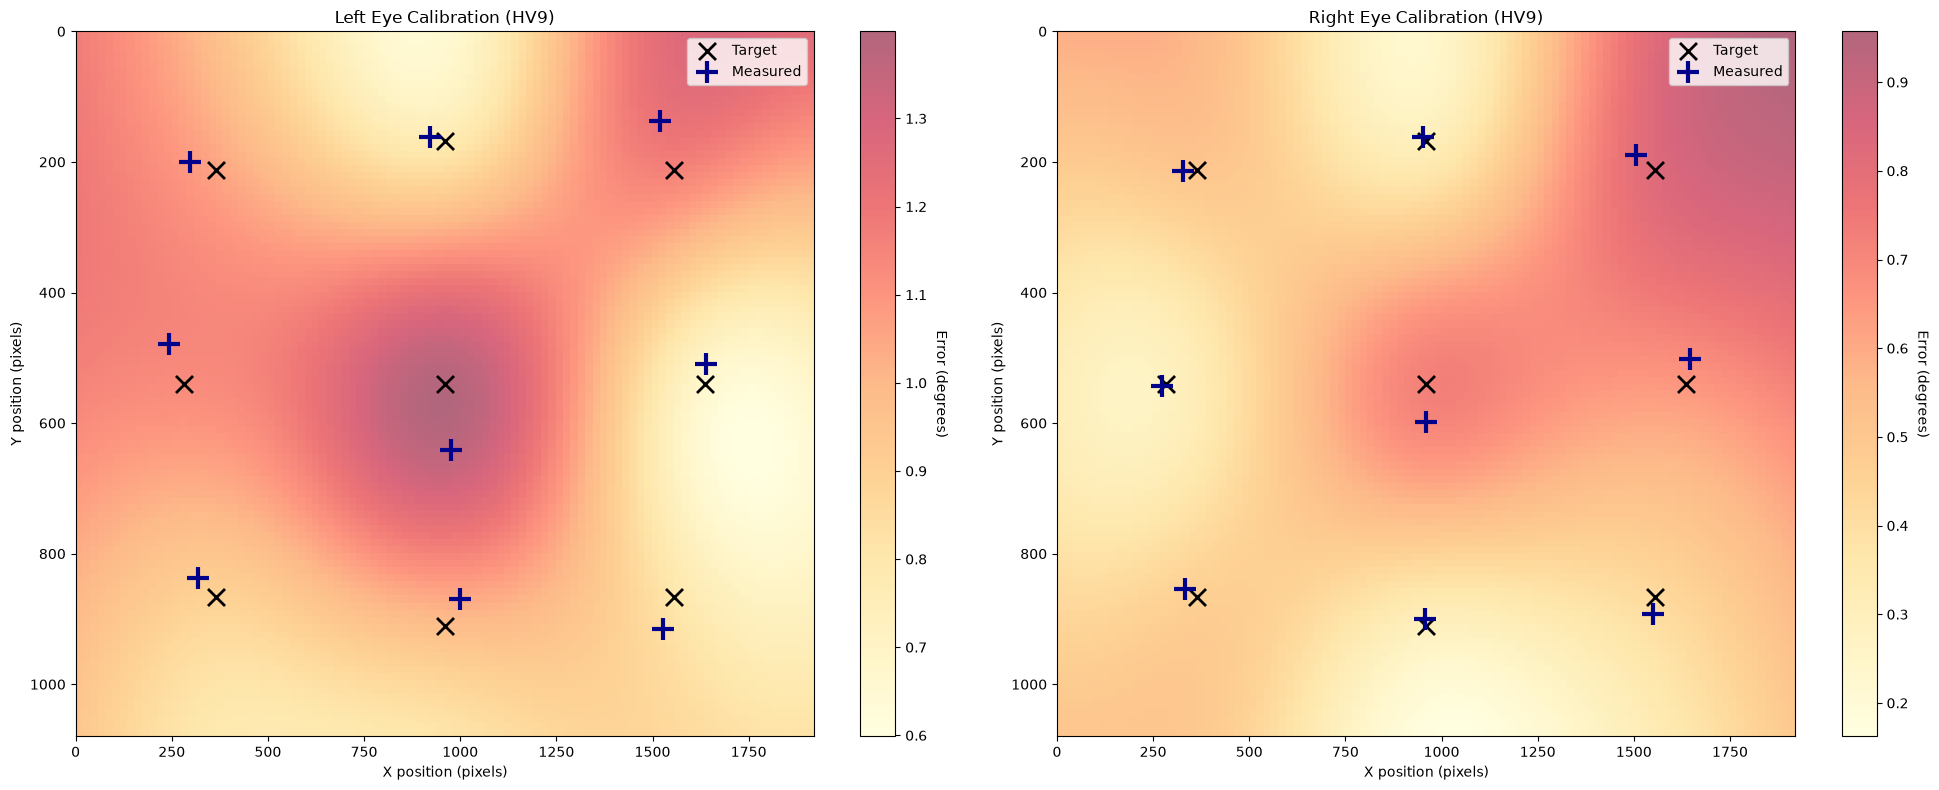

In [5]:
d.plot.plot_calibration();

In this recording, the right eye was measured more accurately than the
left eye, which had errors of more than 1° near the screen center. For
analyses that depend on precise gaze positions, the right eye would be
the better choice.